# 02 — Nettoyage et appariement capteur ↔ station

Le notebook 01 nous a donné les règles. Le script `scripts/02_nettoyer.py` les applique à tous les capteurs. Ici, on regarde ce que chaque règle a retiré, puis on se demande : **une fois nettoyé, à quel point le capteur brut est-il loin de la station ?** C'est le « avant » que le modèle devra améliorer.

Les règles, dans l'ordre :

| | règle | pourquoi |
|---|---|---|
| a | retirer les mesures vides, négatives, au plafond (999,9) ou avec PM2.5 > PM10 | valeurs impossibles (notebook 01) |
| b | retirer les plateaux 0/0 d'au moins une heure | capteur en panne |
| f | écarter un capteur qui a bougé de plus de 1 km | il n'a pas toujours été à côté de sa station |
| c | moyenne par heure UTC, gardée si elle contient au moins 75 % des mesures attendues | comparer heure par heure avec la station |
| d | station : heures valides et vérifiées seulement, −999 = manquant, heure UTC = Start − 1 h | référence propre et à la bonne heure (notebook 01) |
| e | météo DWD de la station la plus proche (humidité, température) | variables du modèle |
| g | contrôle de chaque paire : le capteur suit-il les variations de sa station ? | repérer les capteurs mal placés ou défectueux |

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib import nettoyage as N
from aircalib import parametres as P
from aircalib.metriques import resume, stats_regression
from aircalib.variables import mediane_des_voisins

DONNEES = P.dossier_donnees()
FIGURES = P.RAPPORTS / "figures"
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
entonnoir = pl.read_csv(P.RAPPORTS / "entonnoir.csv")
paires = pl.read_parquet(DONNEES / "propre" / "paires.parquet")
heures = pl.read_parquet(DONNEES / "propre" / "heures_paires.parquet")

## 1. L'entonnoir : ce que chaque règle a retiré

Le script écrit `reports/entonnoir.csv`. Les nombres négatifs sont des retraits.

In [2]:
brutes = entonnoir.filter(pl.col("etape") == "mesures brutes")["nombre"][0]
entonnoir.with_columns(
    pl.when(pl.col("unite") == "mesures")
    .then((100 * pl.col("nombre") / brutes).round(2))
    .alias("% des mesures brutes")
)

etape,unite,nombre,% des mesures brutes
str,str,i64,f64
"""mesures brutes""","""mesures""",148636757,100.0
"""retiré : vide""","""mesures""",-384700,-0.26
"""retiré : code d'erreur (négatif)""","""mesures""",0,0.0
"""retiré : plafond du capteur""","""mesures""",-852621,-0.57
"""retiré : PM2.5 > PM10""","""mesures""",-118,-0.0
"""retiré : plateau 0/0 ≥ 1 h""","""mesures""",-538949,-0.36
"""retiré : capteur déplacé de plus de 1 km""","""mesures""",-3193367,-2.15
"""mesures gardées""","""mesures""",143667002,96.66
"""heures avec au moins une mesure""","""heures""",6098098,null


**En mesures** (148,6 millions au départ) :
- les valeurs impossibles (règle a) retirent 1,24 million de mesures, soit 0,8 % ;
- les plateaux 0/0 d'au moins une heure en retirent 0,54 million (0,36 %). C'est seulement 27 % des 1,98 million de 0/0 comptés au notebook 01 : les autres sont des 0/0 isolés, qu'on garde ;
- la plus grosse perte vient des **12 capteurs déplacés** : 3,2 millions de mesures (2,15 %).

Au total, on garde 96,7 % des mesures.

**En heures :**
- on part de 6,10 millions d'heures avec au moins une mesure ;
- 5,4 % sont incomplètes ;
- 5,3 % des heures restantes n'ont pas de valeur EEA valide ;
- moins de 1 % n'ont pas de météo DWD.

Il reste **5,41 millions d'heures-paires**, dont 4,40 millions (81 %) dans des paires saines (partie 3).

**Ce que ça veut dire :** le nettoyage retire peu de données (3,3 % des mesures, 11 % des heures). Surtout, ce qu'il retire, ce sont des pannes et des trous, pas des épisodes de pollution. On ne rend donc pas le problème artificiellement plus facile.

## 2. Pourquoi « 75 % des mesures attendues » et pas un nombre fixe ?

Le plus simple serait un seuil fixe, par exemple 20 mesures par heure. Mais tous les capteurs n'envoient pas au même rythme. On regarde l'intervalle habituel entre deux mesures (la médiane des écarts) pour chaque capteur apparié actif en mars 2025.

In [3]:
apparies = paires["capteur"].to_list()
cadences = []
for c in apparies:
    fichier = DONNEES / "brut" / "capteurs" / str(c) / "2025-03.parquet"
    if fichier.exists():
        mars = pl.read_parquet(fichier)
        if mars.height > 100:
            cadences.append({"capteur": c, "cadence_s": N.cadence_s(mars)})
cadences = pl.DataFrame(cadences)
print(f"{cadences.height} capteurs actifs en mars 2025")
cadences.group_by(minutes=(pl.col("cadence_s") / 60).round(1)).agg(capteurs=pl.len()).sort(
    "capteurs", descending=True
).head(6)

392 capteurs actifs en mars 2025


minutes,capteurs
f64,u32
2.4,182
2.5,137
5.0,8
2.8,7
3.0,7
4.0,6


Sur les 392 capteurs actifs en mars 2025 :
- **319 (81 %)** envoient une mesure toutes les 2,4–2,5 minutes, soit environ 25 par heure ;
- 6 envoient une mesure par minute (60 par heure) ;
- 8 en envoient une toutes les 5 minutes (12 par heure).

**Ce que ça veut dire :** avec un seuil de 20 mesures par heure, un capteur à 5 minutes n'aurait jamais une seule heure valide, et une heure remplie au tiers suffirait pour un capteur à 1 minute.

**Décision :** pour chaque capteur, on calcule sa cadence (la médiane des écarts entre deux mesures). Une heure est gardée si elle contient au moins 75 % des mesures attendues à cette cadence (règle c, `COMPLETUDE_MIN`).

## 3. Le contrôle des paires (règle g)

Un capteur peut être propre au sens des règles a–f et pourtant ne pas mesurer le même air que sa station : capteur à l'intérieur, collé à une cheminée, ventilateur en panne, ou mauvaise position déclarée. On reprend l'idée du notebook 01 : on calcule la corrélation entre les variations horaires du capteur et celles de sa station, maintenant que l'horloge est corrigée. Une paire est jugée **défectueuse** si cette corrélation est inférieure à 0,1, ou si elle a moins de 500 heures pour en juger.

paires contrôlées : 541
  saines : 419
  défectueuses : 122
    dont trop peu d'heures pour juger : 19


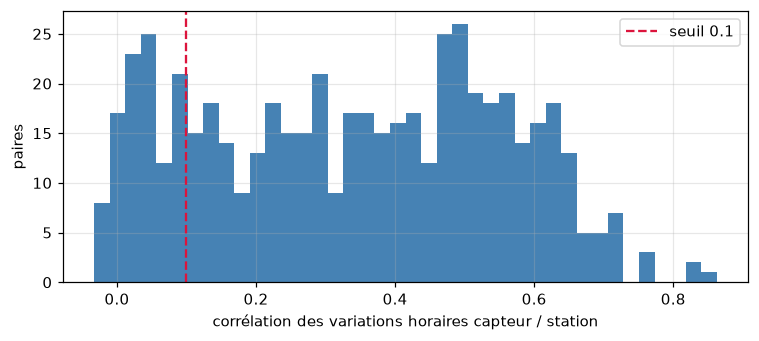

In [4]:
print(f"paires contrôlées : {paires['paire_saine'].is_not_null().sum()}")
print(f"  saines : {paires['paire_saine'].sum()}")
print(f"  défectueuses : {(~paires['paire_saine']).sum()}")
print(f"    dont trop peu d'heures pour juger : {(paires['heures_controle'] < P.HEURES_MIN_CONTROLE).sum()}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(paires["correlation_variations"].drop_nulls().drop_nans(), bins=40, color="steelblue")
ax.axvline(P.CORRELATION_MIN, color="crimson", ls="--", label=f"seuil {P.CORRELATION_MIN}")
ax.set_xlabel("corrélation des variations horaires capteur / station")
ax.set_ylabel("paires")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "02_controle_des_paires.png")

On a pu contrôler 541 paires : 569 moins les 12 capteurs déplacés, et 16 paires sans aucune heure commune avec leur station.
- **419 paires sont saines (77 %)** ;
- **122 sont défectueuses**, dont 19 seulement parce qu'elles ont moins de 500 heures pour juger.

L'histogramme est très étalé, de 0 à 0,85. Il y a un petit paquet de paires autour de 0 : des capteurs dont les variations n'ont aucun rapport avec celles de leur station.

Voici la paire défectueuse la plus nette (parmi celles qui ont assez d'heures), sur son mois le plus rempli :

capteur,station,type_station,distance_km,correlation_variations,heures_controle
i64,str,str,f64,f64,i64
5706,"""DEBE061""","""traffic""",0.985765,-0.032696,11793


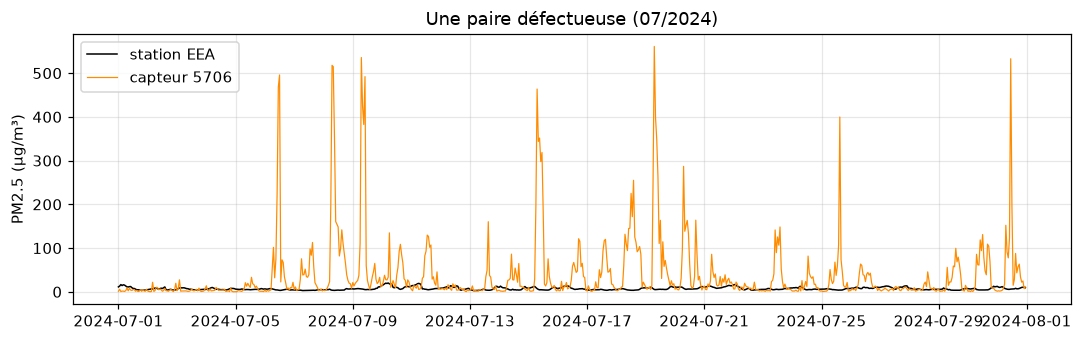

In [5]:
mauvaise = paires.filter(~pl.col("paire_saine"), pl.col("heures_controle") > 2000).sort(
    "correlation_variations"
)["capteur"][0]
exemple = heures.filter(pl.col("capteur") == mauvaise)
mois = exemple["heure"].dt.truncate("1mo").mode()[0]
exemple = exemple.filter(pl.col("heure").dt.truncate("1mo") == mois)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(exemple["heure"], exemple["reference"], color="k", lw=1, label="station EEA")
ax.plot(exemple["heure"], exemple["pm25"], color="darkorange", lw=0.8, label=f"capteur {mauvaise}")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title(f"Une paire défectueuse ({mois:%m/%Y})")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "02_paire_defectueuse.png")
paires.filter(pl.col("capteur") == mauvaise).select(
    "capteur", "station", "type_station", "distance_km", "correlation_variations", "heures_controle"
)

Le capteur 5706 est à 990 m d'une station de trafic à Berlin, et sa corrélation avec elle est de −0,03 sur près de 12 000 heures. En juillet 2024, il monte presque chaque soir à 400–550 µg/m³, alors que la station reste sous 20 µg/m³.

**Ce que ça veut dire :** ce capteur mesure une source très locale (fumée de barbecue ou de cheminée, cigarette sur un balcon ?), pas l'air que mesure la station. Aucune correction ne pourra le rapprocher de la station, et ce n'est pas le rôle du modèle.

**Décision :** les paires défectueuses ne servent **pas** à l'apprentissage, car le modèle apprendrait à corriger un capteur qui ne mesure pas le bon air. On les garde quand même pour l'évaluation, à part, pour montrer ce que donnerait le modèle si on ne les filtrait pas.

## 4. L'« avant » : le capteur brut face à la station

On calcule maintenant, sur les paires saines, les mêmes indicateurs que pour les modèles, en prenant comme « prédiction » la mesure brute du capteur.

**Les indicateurs.**
- Le **RMSE** est l'erreur quadratique moyenne, $\sqrt{\tfrac1n\sum (\hat y - y)^2}$, en µg/m³. Il est très sensible aux grosses erreurs.
- Le **MAE** est l'erreur absolue moyenne, $\tfrac1n\sum |\hat y - y|$.
- Les **cibles EPA** sont celles de l'agence américaine de l'environnement pour les capteurs à bas coût. Pour chaque paire, on régresse le capteur sur la station, $\hat y = a\,y + b$. La paire « passe » si :
  - $R^2 \ge 0{,}70$ ;
  - la pente $a$ est entre 0,65 et 1,35 ;
  - l'ordonnée $b$ est entre −5 et +5 µg/m³ ;
  - et le RMSE est d'au plus 7 µg/m³.

  On compte la part des paires qui passent, sur les valeurs horaires et sur les moyennes journalières. Une paire n'est notée que si elle a au moins 500 heures, ou 30 jours complets.

In [6]:
saines = heures.filter(pl.col("paire_saine")).with_columns(prediction=pl.col("pm25"))
avant = resume(saines)
{k: round(v, 3) for k, v in avant.items()}

{'heures': 4401479,
 'rmse': 12.417,
 'mae': 5.164,
 'r2_global': 0.141,
 'pente_globale': 0.621,
 'paires_notees': 419,
 'r2_median_par_paire': 0.687,
 'pente_mediane_par_paire': 0.621,
 'pct_epa_horaire': 25.298,
 'pct_epa_journalier': 40.931}

Sur les 419 paires saines (4,4 millions d'heures), le capteur brut donne :
- un **RMSE de 12,4 µg/m³** et un **MAE de 5,2 µg/m³** ;
- un **R² médian par paire de 0,69** et une **pente médiane de 0,62** ;
- **25 % des paires passent les cibles EPA** en horaire, **41 %** en moyenne journalière.

**Ce que ça veut dire :**
- Le capteur suit plutôt bien les variations : un R² de 0,69, c'est presque la cible de 0,70.
- Mais il **sous-estime** : avec une pente de 0,62, il voit environ 60 % de ce que mesure la station.
- Le RMSE est plus de deux fois plus grand que le MAE : il y a peu d'erreurs, mais certaines sont énormes (des pics de fumée locale comme ci-dessus, même dans des paires saines).

Pourquoi les paires échouent-elles ? (Une paire peut échouer sur plusieurs cibles à la fois.)

In [7]:
par_paire = stats_regression(saines, ["capteur"]).filter(pl.col("n") >= P.HEURES_MIN_PAIRE)
raisons = par_paire.select(
    r2_trop_bas=(pl.col("r2") < P.EPA_R2_MIN).mean(),
    pente_hors_cible=(~pl.col("pente").is_between(*P.EPA_PENTE)).mean(),
    ordonnee_hors_cible=(~pl.col("ordonnee").is_between(*P.EPA_ORDONNEE)).mean(),
    rmse_trop_grand=(pl.col("rmse") > P.EPA_RMSE_MAX).mean(),
)
raisons.select((pl.all() * 100).round(1))

r2_trop_bas,pente_hors_cible,ordonnee_hors_cible,rmse_trop_grand
f64,f64,f64,f64
53.5,55.8,3.3,38.7


- 54 % des paires échouent sur le R² ;
- 56 % échouent sur la pente ;
- 39 % échouent sur le RMSE ;
- seulement 3 % échouent sur l'ordonnée.

**Ce que ça veut dire :** le capteur n'a presque pas de décalage constant. Ses défauts sont un **problème d'échelle** (la pente) et du **bruit** (le R²). C'est ce que le modèle devra corriger.

On regarde enfin le nuage capteur / station, puis le rapport capteur / station selon l'humidité de l'air (on ne garde que les heures où la station mesure au moins 5 µg/m³, pour que le rapport ait un sens).

classe,rapport_median,heures
i64,f64,u32
30,0.37,113872
40,0.38,188709
50,0.4,267147
60,0.43,373742
70,0.47,552858
80,0.56,742107
90,0.7,885147


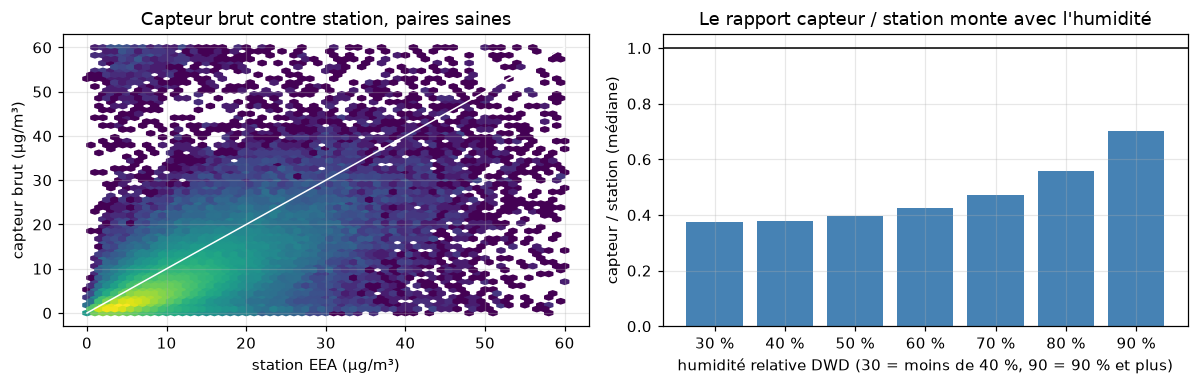

In [8]:
humidite = (
    saines.filter(pl.col("reference") >= 5)
    .with_columns(classe=(pl.col("humidite") // 10 * 10).clip(30, 90).cast(pl.Int64))
    .group_by("classe")
    .agg(rapport_median=(pl.col("pm25") / pl.col("reference")).median(), heures=pl.len())
    .sort("classe")
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
echantillon = saines.sample(200_000, seed=P.GRAINE)
axes[0].hexbin(
    echantillon["reference"],
    echantillon["pm25"],
    gridsize=60,
    bins="log",
    extent=(0, 60, 0, 60),
    cmap="viridis",
)
axes[0].plot([0, 60], [0, 60], color="w", lw=1)
axes[0].set_xlabel("station EEA (µg/m³)")
axes[0].set_ylabel("capteur brut (µg/m³)")
axes[0].set_title("Capteur brut contre station, paires saines")
axes[1].bar(humidite["classe"].cast(pl.Utf8) + " %", humidite["rapport_median"], color="steelblue")
axes[1].axhline(1, color="k", lw=1)
axes[1].set_xlabel("humidité relative DWD (30 = moins de 40 %, 90 = 90 % et plus)")
axes[1].set_ylabel("capteur / station (médiane)")
axes[1].set_title("Le rapport capteur / station monte avec l'humidité")
fig.tight_layout()
fig.savefig(FIGURES / "02_avant_correction.png")
humidite.with_columns(pl.col("rapport_median").round(2))

À gauche, la plupart des points sont sous la diagonale : le capteur mesure moins que la station, avec une grande dispersion. À droite, le rapport médian capteur / station passe de **0,37** par air sec (moins de 40 % d'humidité) à **0,47** vers 70 %, puis à **0,70** au-delà de 90 %.

**Ce que ça veut dire :** le facteur de correction n'est pas constant. Il change presque du simple au double selon l'humidité, et il change surtout au-dessus de 70 %. Ça s'explique : les particules absorbent de l'eau et grossissent, et le capteur optique les compte comme plus grosses.

Une correction du type « multiplier par 1,6 » ne peut donc pas marcher. Il faut une correction qui dépend de l'humidité, et pas forcément de façon linéaire.

> **[À ÉCRIRE PAR L'ÉQUIPE]** — Interprétation de l'« avant » : qu'est-ce qui nous a surpris dans ces chiffres, et qu'en déduit-on pour le modèle ? (Quelques lignes.)

## 5. Les voisins : une information que la station ne donne pas

Plusieurs capteurs SDS011 sont souvent installés dans le même quartier. Leur médiane, à la même heure, renseigne sur le niveau de pollution local, sans jamais utiliser la station. Elle aide aussi à repérer quand un capteur s'écarte de ses voisins (humidité, panne passagère). On définit donc, pour chaque heure-paire, la **médiane des voisins** : la médiane du PM2.5 des autres capteurs à 3 km ou moins, s'ils sont au moins 3.

Au départ, nos « voisins » étaient seulement les capteurs appariés, c'est-à-dire ceux qu'on avait déjà téléchargés. On compare la part des heures qui ont une médiane des voisins dans ce cas, et quand on ajoute les capteurs SDS011 non appariés situés à moins de 3 km d'un capteur apparié.

In [9]:
positions = pl.read_parquet(DONNEES / "propre" / "positions.parquet")
mesures = pl.read_parquet(DONNEES / "propre" / "pm25_horaire.parquet")
base = heures.select("capteur", "heure", "pm25")
seulement_apparies = positions.filter(pl.col("role") == "apparié")
couverture = {
    "voisins = capteurs appariés seulement": mediane_des_voisins(
        base, mesures.join(seulement_apparies.select("capteur"), on="capteur"), seulement_apparies
    ),
    "voisins = appariés + capteurs voisins non appariés": mediane_des_voisins(base, mesures, positions),
}
pl.DataFrame(
    [
        {
            "choix": nom,
            "heures avec ≥ 3 voisins (%)": round(100 * t["mediane_voisins"].is_not_null().mean(), 1),
        }
        for nom, t in couverture.items()
    ]
)

choix,heures avec ≥ 3 voisins (%)
str,f64
"""voisins = capteurs appariés seulement""",60.3
"""voisins = appariés + capteurs voisins non appariés""",79.0


**Avec les seuls capteurs appariés, seulement 60 % des heures ont une médiane des voisins.** En ajoutant les 808 capteurs SDS011 non appariés situés à moins de 3 km d'un capteur apparié, on passe à **79 %**.

Ce choix a un coût : il faut télécharger 1 377 capteurs au lieu de 569, soit environ une heure et demie de téléchargement en plus.

On l'a fait parce que notre premier entraînement complet, avec les seuls capteurs appariés comme voisins, montrait que **les heures sans voisins étaient le point faible du modèle** :
- 37 % des paires passaient les cibles EPA sur ces heures ;
- contre 79 % sur les heures avec voisins.

Ces chiffres sont gardés dans `reports/resultats_premier_essai.csv` et sont comparés au résultat final dans le notebook 04. Plutôt que de compliquer le modèle, on lui a donné plus d'information là où il en manquait.

## Ce qu'on retient

- **Nettoyage :** les règles retirent peu de données (3,3 % des mesures, 11 % des heures), surtout des capteurs déplacés et des heures incomplètes. La complétude est jugée par rapport à la cadence propre de chaque capteur.
- **Paires défectueuses :** 122 paires sur 541 ne suivent pas leur station. Elles sont exclues de l'apprentissage et évaluées à part.
- **L'« avant » :** sur les paires saines, le capteur brut ne passe les cibles EPA que pour **25 % des paires** en horaire (41 % en journalier). Il sous-estime (pente 0,62), et son facteur d'erreur dépend fortement de l'humidité.
- **Les voisins :** en ajoutant les capteurs non appariés, 79 % des heures ont une médiane des voisins.

Le script `03_construire_variables.py` construit ensuite les variables du modèle (notebook 03).